# Project 31: Job Market Skill Demand (Q1 sampai Q14)
Semua angka dibaca dari CSV di `project/results/`. Data: 48 lowongan unik Jobstreet, satu kali ambil (Oktober 2026). Sampel kecil.

In [1]:
import pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
R = Path('..') / '2-analysis'
P = Path('..') / '1-data-preparation'
rd = lambda p, n: pd.read_csv(p / n)
pd.options.display.float_format = '{:,.3f}'.format

## Data dan cleaning (Q14)

In [2]:
display(rd(P, 'data_quality_summary.csv'), rd(P, 'cleaning_log.csv')[['rule','description','rows_found']], rd(R, 'duplicate_sensitivity.csv'))

,item,value
0,Baris jobs_target_all.csv (mentah),51
1,Baris jobs_detail.csv (mentah),53
2,Lowongan setelah digabung dengan deskripsi,51
3,Duplikat dibuang,3
4,Lowongan unik dianalisis,48
5,Salary tercantum,9
6,Salary kosong,39
7,Kota/wilayah unik,8
8,Perusahaan unik,35


,rule,description,rows_found
0,C1,Job ID ganda di jobs_target_all.csv atau jobs_...,0
1,C2,Deskripsi tanpa baris di daftar lowongan,2
2,C3,Lowongan tanpa deskripsi,0
3,C4,Spasi khusus (NBSP) dan spasi ganda pada teks,9
4,C5,Salary ditulis sebagai teks bebas ('Rp 7.000.0...,9
5,C6,listing_date berformat UTC (ISO 8601),51
6,C7,"Nama kota tidak seragam (kecamatan, provinsi, ...",50
7,C8,Deskripsi identik (iklan sama diposting ulang ...,3
8,C9,Judul dan perusahaan sama tetapi deskripsi ber...,0


,skill,jobs_raw,n_raw,share_raw,jobs_clean,n_clean,share_clean,diff
0,Excel,33,51,0.647,30,48,0.625,-0.022
1,SQL,22,51,0.431,22,48,0.458,0.027
2,Power BI,21,51,0.412,21,48,0.438,0.026
3,Tableau,17,51,0.333,17,48,0.354,0.021
4,Python,15,51,0.294,15,48,0.312,0.018
5,Looker Studio,9,51,0.176,9,48,0.188,0.011


## Q1, Q2 Skill dan kombinasinya

,skill,category,jobs,total,share,ci_low,ci_high
0,Excel,Spreadsheet,30,48,0.625,0.484,0.748
1,Dashboard,Konsep,28,48,0.583,0.443,0.712
2,SQL,Database & query,22,48,0.458,0.326,0.597
3,Power BI,Tools BI,21,48,0.438,0.307,0.577
4,Tableau,Tools BI,17,48,0.354,0.234,0.496
5,Python,Pemrograman,15,48,0.312,0.199,0.453
6,Looker Studio,Tools BI,9,48,0.188,0.102,0.319
7,Google Sheets,Spreadsheet,7,48,0.146,0.072,0.272
8,ETL,Data engineering,5,48,0.104,0.045,0.222
9,Statistik,Statistik,5,48,0.104,0.045,0.222


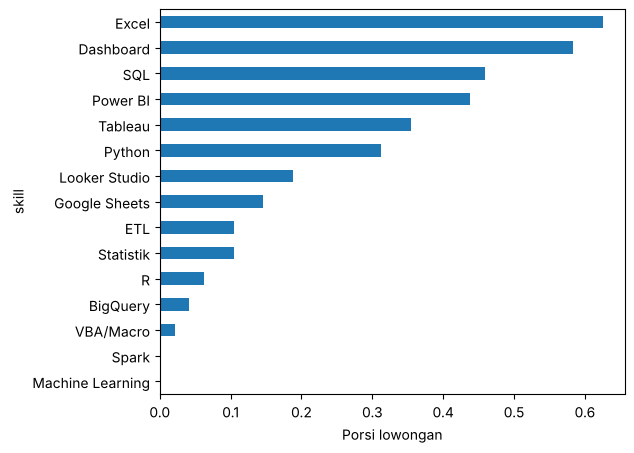

,skill_a,skill_b,jobs
0,Power BI,SQL,15
1,Power BI,Tableau,15
2,Python,SQL,15
3,SQL,Tableau,13
4,Excel,Power BI,12
5,Excel,SQL,12
6,Power BI,Python,11
7,Python,Tableau,10
8,Excel,Python,8
9,Excel,Tableau,8


In [3]:
s = rd(R, 'skill_share.csv'); ci = rd(R, 'share_ci.csv')
display(s.merge(ci[['item','ci_low','ci_high']], left_on='skill', right_on='item', how='left').drop(columns='item'))
s.sort_values('share').plot.barh(x='skill', y='share', legend=False, figsize=(6,5)); plt.xlabel('Porsi lowongan'); plt.show()
display(rd(R, 'skill_cooc.csv').head(10))

## Q3 Level

In [4]:
display(rd(R, 'level_summary.csv'), rd(R, 'skill_by_level.csv'))

,level,jobs,with_python
0,Tidak disebut,37,11
1,Senior,10,4
2,Junior,1,0


,level,n_level,skill,jobs,share
0,Senior,10,Power BI,5,0.500
1,Senior,10,SQL,5,0.500
2,Senior,10,Tableau,5,0.500
3,Senior,10,Excel,4,0.400
4,Senior,10,Python,4,0.400
5,Tidak disebut,37,Excel,26,0.703
6,Tidak disebut,37,SQL,17,0.459
7,Tidak disebut,37,Power BI,16,0.432
8,Tidak disebut,37,Tableau,12,0.324
9,Tidak disebut,37,Python,11,0.297


## Q4, Q5, Q6 Salary dan cakupan

In [5]:
display(rd(R, 'salary_by_skill.csv'), rd(R, 'salary_coverage.csv'))

,skill,n_salary,median_min,median_max,lowest_min,highest_max
0,Excel,8,"6,144,400.000","8,000,000.000",2500000,10500000
1,Dashboard,5,"5,750,000.000","7,500,000.000",2500000,9000000
2,Power BI,4,"6,375,000.000","7,750,000.000",2500000,10000000
3,SQL,4,"6,375,000.000","8,500,000.000",2500000,10500000
4,Tableau,3,"5,750,000.000","7,000,000.000",2500000,8500000
5,Google Sheets,2,"3,750,000.000","5,000,000.000",2500000,6500000
6,Looker Studio,2,"6,375,000.000","7,750,000.000",5750000,8500000
7,ETL,1,"2,500,000.000","3,500,000.000",2500000,3500000
8,Python,1,"2,500,000.000","3,500,000.000",2500000,3500000
9,R,1,"2,500,000.000","3,500,000.000",2500000,3500000


,dimension,val,jobs,with_salary,coverage
0,Kota,Jakarta,31,4,0.129
1,Kota,Tangerang,6,1,0.167
2,Kota,Surabaya,5,2,0.400
3,Kota,Medan,2,0,0.000
4,Kota,Bali,1,0,0.000
5,Kota,Bandung,1,1,1.000
6,Kota,Tidak spesifik,1,0,0.000
7,Kota,Yogyakarta,1,1,1.000
8,Level,Tidak disebut,37,8,0.216
9,Level,Senior,10,1,0.100


## Q5, Q7, Q8 Kota dan bidang kerja (pengganti industri)

In [6]:
display(rd(R, 'city_summary.csv'), rd(R, 'industry_summary.csv'))

,city,jobs,share,n_salary,median_min,median_max
0,Jakarta,31,0.646,4,"7,000,000.000","8,750,000.000"
1,Tangerang,6,0.125,1,"5,000,000.000","6,500,000.000"
2,Surabaya,5,0.104,2,"4,894,400.000","6,250,000.000"
3,Medan,2,0.042,0,NaN,NaN
4,Bali,1,0.021,0,NaN,NaN
5,Bandung,1,0.021,1,"7,000,000.000","10,500,000.000"
6,Tidak spesifik,1,0.021,0,NaN,NaN
7,Yogyakarta,1,0.021,1,"2,500,000.000","3,500,000.000"


,industry,jobs,share,n_salary,median_min,median_max
0,Pengembangan & Administrasi Database,12,0.250,2,"6,375,000.000","8,750,000.000"
1,Analis Bisnis/Sistem,10,0.208,3,"7,000,000.000","8,500,000.000"
2,"Matematika, Statistik & Teknik Informasi",7,0.146,1,"5,288,800.000","7,500,000.000"
3,Analisis & Pelaporan,4,0.083,2,"6,000,000.000","7,750,000.000"
4,Kepatuhan & Resiko,3,0.062,0,NaN,NaN
5,Analis,2,0.042,0,NaN,NaN
6,Manajemen & Dukungan,2,0.042,0,NaN,NaN
7,Asisten Administratif,1,0.021,0,NaN,NaN
8,Entri Data & Pengolahan Kata,1,0.021,0,NaN,NaN
9,Jasa Otomotif,1,0.021,1,"4,500,000.000","5,000,000.000"


## Q9 Remote atau hybrid

In [7]:
display(rd(R, 'remote_share.csv'))

,jobs,remote_hybrid_jobs,share
0,48,2.000,0.042


## Q10, Q11 Tren (belum bisa dijawab: satu kali ambil, tidak ada data lama)

In [8]:
display(rd(R, 'weekly_jobs.csv'), rd(R, 'old_study_compare.csv'))

,week_start,jobs,cumulative_jobs,change_vs_prev
0,2026-03-23,1,1.000,NaN
1,2026-07-13,1,2.000,0.000
2,2026-08-31,1,3.000,0.000
3,2026-09-07,1,4.000,0.000
4,2026-09-14,2,6.000,1.000
5,2026-09-21,12,18.000,10.000
6,2026-09-28,9,27.000,-3.000
7,2026-10-05,9,36.000,0.000
8,2026-10-12,12,48.000,3.000


,old_skill,skill,old_jobs,new_jobs,old_pct,new_pct,selisih_jumlah,status
0,Excel,Excel,30,30.000,62.500,62.500,0.000,Sama
1,Dashboard,Dashboard,28,28.000,58.300,58.300,0.000,Sama
2,SQL,SQL,22,22.000,45.800,45.800,0.000,Sama
3,Power BI,Power BI,21,21.000,43.800,43.800,0.000,Sama
4,Problem solving,Problem solving,21,NaN,43.800,NaN,NaN,Tidak ada di kamus baru
5,Komunikasi,Komunikasi,21,NaN,43.800,NaN,NaN,Tidak ada di kamus baru
6,Visualisasi,Visualisasi,20,NaN,41.700,NaN,NaN,Tidak ada di kamus baru
7,Tableau,Tableau,17,17.000,35.400,35.400,0.000,Sama
8,Python,Python,15,15.000,31.200,31.200,0.000,Sama
9,Bahasa Inggris,Bahasa Inggris,11,NaN,22.900,NaN,NaN,Tidak ada di kamus baru


## Q12 Skill match (estimated)

In [9]:
display(rd(R, 'skill_match.csv'), rd(R, 'skill_match_scenarios.csv'), rd(R, 'skill_next.csv'))

,boleh_kurang,bisa_dilamar,total,share
0,0,17,48,0.354
1,1,28,48,0.583
2,2,37,48,0.771


,skenario,bisa_dilamar,total,share
0,Excel,15,48,0.312
1,Excel + SQL,17,48,0.354
2,Excel + SQL + Python,17,48,0.354
3,Excel + SQL + Python + Power BI,21,48,0.438


,skill,tambahan_lowongan,tambahan_share,share_setelah
0,Google Sheets,4,0.083,0.438
1,Power BI,4,0.083,0.438
2,Statistik,2,0.042,0.396
3,ETL,1,0.021,0.375
4,BigQuery,0,0.000,0.354
5,Looker Studio,0,0.000,0.354
6,R,0,0.000,0.354
7,Tableau,0,0.000,0.354
8,VBA/Macro,0,0.000,0.354


## Q13 Validasi skill extraction

In [10]:
display(rd(R, 'skill_eval.csv'), rd(R, 'skill_eval_errors.csv'))

,skill,labeled,extracted,tp,fp,fn,precision,recall
0,Excel,14,14,14,0,0,1.000,1.000
1,Google Sheets,3,3,3,0,0,1.000,1.000
2,SQL,11,11,11,0,0,1.000,1.000
3,BigQuery,0,0,0,0,0,NaN,NaN
4,Python,7,7,7,0,0,1.000,1.000
5,R,1,1,1,0,0,1.000,1.000
6,VBA/Macro,1,1,1,0,0,1.000,1.000
7,Power BI,6,6,6,0,0,1.000,1.000
8,Tableau,4,4,4,0,0,1.000,1.000
9,Looker Studio,3,3,3,0,0,1.000,1.000


,job_id,skill,type
0,93403701,Statistik,"FN (label ada, kamus tidak menemukan)"
1,95095619,Machine Learning,"FN (label ada, kamus tidak menemukan)"


## Hipotesis Design

In [11]:
display(rd(R, 'hypotheses.csv'))

,no,hypothesis,evidence,p_value,verdict
0,1,SQL dan Excel muncul di lebih dari 60% lowongan.,SQL 22/48; Excel 30/48,0.983,Sebagian
1,2,Jakarta menyumbang lebih dari separuh lowongan.,Jakarta 31/48,0.030,Terbukti
2,3,Kurang dari 30% lowongan mencantumkan salary.,Salary tercantum 9/48,0.057,Sebagian
3,4,Python lebih sering diminta di level senior di...,"Senior 4/10, Junior 0/1; kelompok < 5 lowongan",NaN,Sebagian
4,5,Power BI lebih sering diminta dibanding Tableau.,"Power BI 21/48, Tableau 17/48; hanya Power BI ...",0.145,Sebagian
